=== 1D Wasserstein distances ===
Good subset (1D): 0.052
Bad subset  (1D): 2.944

=== 1D tails vs mean ===
Same mean, heavier tails: 0.397
Same tails, shifted mean: 0.543
Match both (best case)  : 0.086

=== Sliced Wasserstein distances ===
2D Good subset: 0.069
2D Bad subset : 2.708
3D Good subset: 0.067
3D Bad subset : 2.567


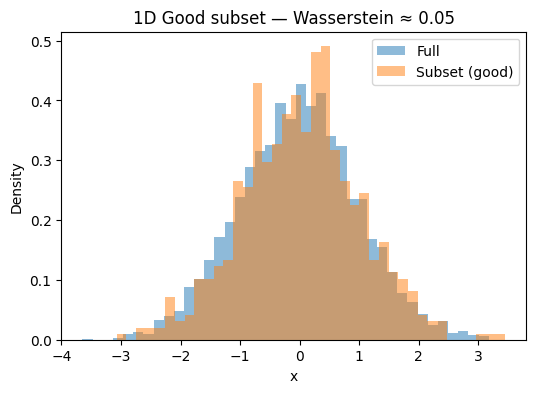

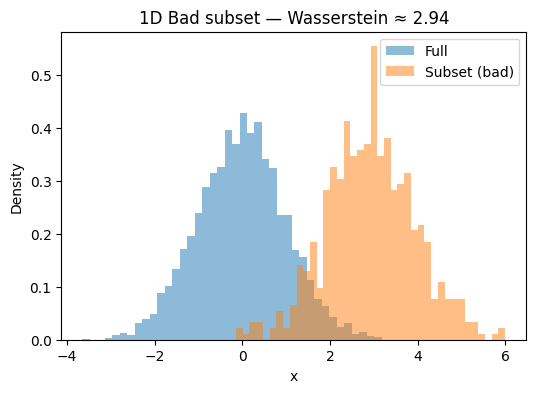

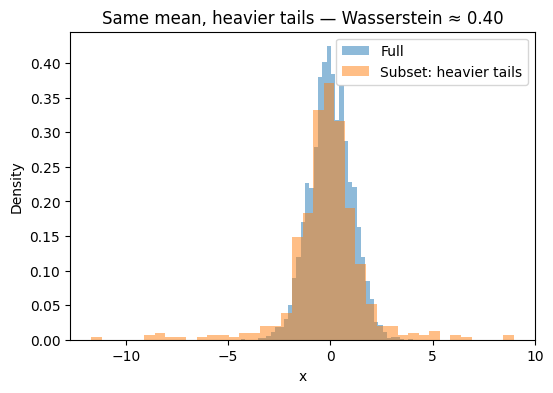

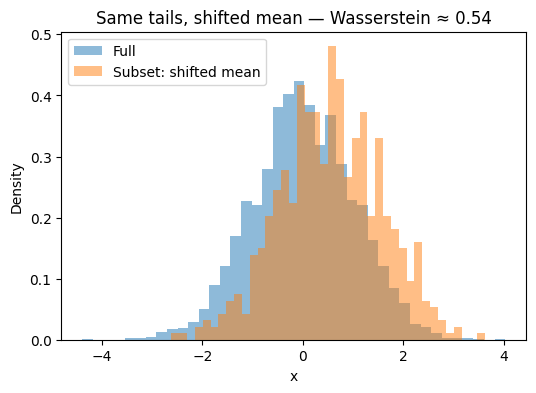

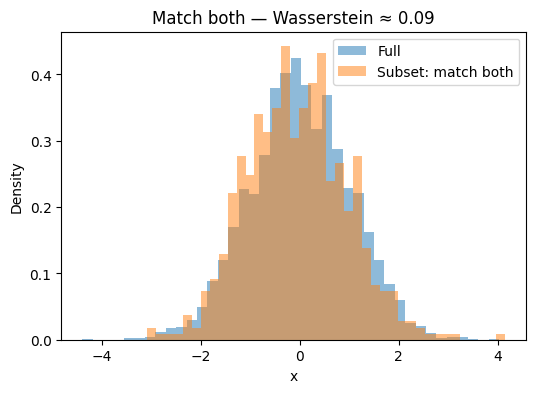

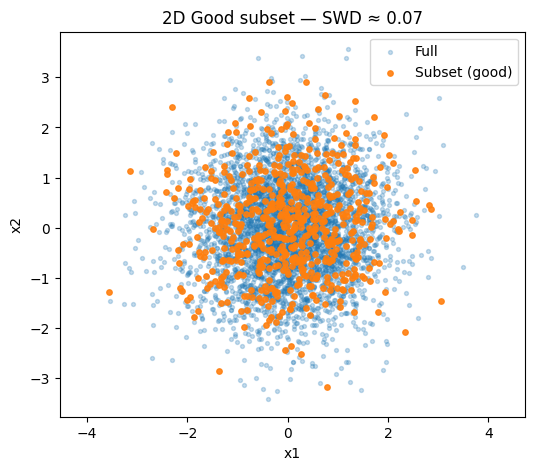

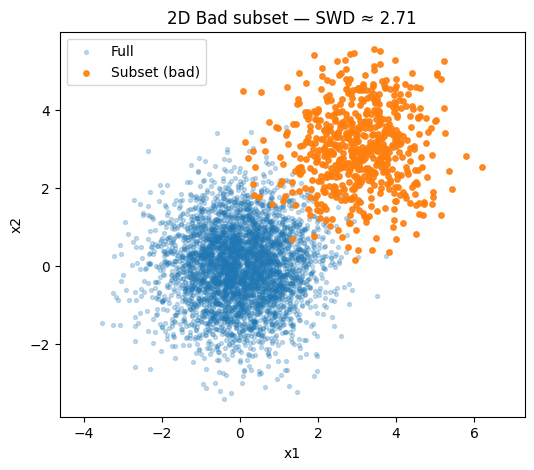

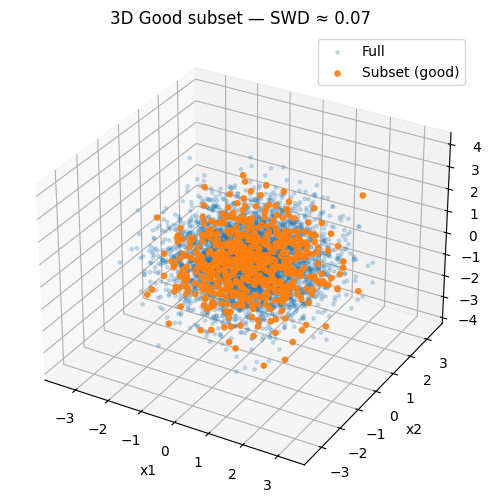

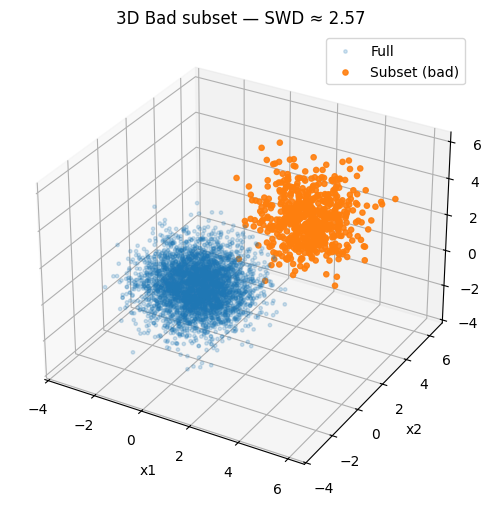

In [1]:
# CHATGPT

# Numerical + visual intuition for (sliced) Wasserstein distances in 1D/2D/3D
#
# How to use:
# - Run this cell as-is to reproduce all figures and printed distances.
# - Tweak the "CONFIG" parameters to experiment (sample sizes, shifts, tail heaviness, #projections).
#
# NOTE on plots: the environment requires one chart per figure and matplotlib (no seaborn).

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import wasserstein_distance, norm
from sklearn.datasets import make_blobs


# -----------------------------
# Utility: sliced Wasserstein
# -----------------------------
def _normalize(v: np.ndarray) -> np.ndarray:
    return v / np.linalg.norm(v, axis=1, keepdims=True)


def sliced_wasserstein_distance(
    X: np.ndarray, Y: np.ndarray, n_projections: int = 256, random_state: int = 0
) -> float:
    """
    Approximate the Wasserstein-1 distance in R^d by averaging
    1D Wasserstein distances along random projections (SWD).
    """
    rng = np.random.default_rng(random_state)
    X = np.asarray(X, dtype=float)
    Y = np.asarray(Y, dtype=float)
    assert X.shape[1] == Y.shape[1], "X and Y must have the same dimension"
    d = X.shape[1]
    # Random directions on the unit sphere in R^d
    dirs = rng.normal(size=(n_projections, d))
    dirs = _normalize(dirs)
    swd_vals = []
    for u in dirs:
        Xu = X @ u
        Yu = Y @ u
        swd_vals.append(wasserstein_distance(Xu, Yu))
    return float(np.mean(swd_vals))


# -----------------------------
# CONFIG (edit these to play)
# -----------------------------
RNG = np.random.default_rng(42)
N_FULL = 4000
N_SUB = 600
N_PROJ = 256

# 1) "Good" vs "Bad" examples (same as the narrative)
#    Full: standard normal
full_1d = RNG.normal(0.0, 1.0, N_FULL)
good_sub_1d = RNG.normal(0.0, 1.0, N_SUB)  # close match
bad_sub_1d = RNG.normal(3.0, 1.0, N_SUB)  # mean-shifted

# 2) Tail vs mean examples (PDF/shape manipulations)
#    Full: standard normal
full_tails = RNG.normal(0.0, 1.0, N_FULL)

# a) Same mean, heavier tails (mixture increases kurtosis, keeps mean ~ 0)
mix_mask = RNG.uniform(0, 1, N_SUB) < 0.10  # 10% heavy-tailed component
tails_same_mean = RNG.normal(0.0, 1.0, N_SUB)
tails_same_mean[mix_mask] = RNG.normal(0.0, 5.0, mix_mask.sum())

# b) Same tails (variance), different mean
same_tails_diff_mean = RNG.normal(0.5, 1.0, N_SUB)

# c) Same mean & tails (best match)
match_both = RNG.normal(0.0, 1.0, N_SUB)

# 3) 2D and 3D datasets
full_2d, _ = make_blobs(
    n_samples=N_FULL, centers=[(0, 0)], cluster_std=1.0, random_state=7
)
good_2d, _ = make_blobs(
    n_samples=N_SUB, centers=[(0, 0)], cluster_std=1.0, random_state=8
)
bad_2d, _ = make_blobs(
    n_samples=N_SUB, centers=[(3, 3)], cluster_std=1.0, random_state=9
)

full_3d, _ = make_blobs(
    n_samples=N_FULL,
    centers=[(0, 0, 0)],
    cluster_std=1.0,
    n_features=3,
    random_state=11,
)
good_3d, _ = make_blobs(
    n_samples=N_SUB, centers=[(0, 0, 0)], cluster_std=1.0, n_features=3, random_state=12
)
bad_3d, _ = make_blobs(
    n_samples=N_SUB, centers=[(3, 3, 3)], cluster_std=1.0, n_features=3, random_state=13
)

# -----------------------------
# 1D: Compute numeric distances
# -----------------------------
wd_good_1d = wasserstein_distance(full_1d, good_sub_1d)
wd_bad_1d = wasserstein_distance(full_1d, bad_sub_1d)

# Tail/mean cases
wd_same_mean_heavy_tails = wasserstein_distance(full_tails, tails_same_mean)
wd_same_tails_diff_mean = wasserstein_distance(full_tails, same_tails_diff_mean)
wd_match_both = wasserstein_distance(full_tails, match_both)

# -----------------------------
# 2D / 3D SWD distances
# -----------------------------
swd_good_2d = sliced_wasserstein_distance(
    full_2d, good_2d, n_projections=N_PROJ, random_state=123
)
swd_bad_2d = sliced_wasserstein_distance(
    full_2d, bad_2d, n_projections=N_PROJ, random_state=123
)

swd_good_3d = sliced_wasserstein_distance(
    full_3d, good_3d, n_projections=N_PROJ, random_state=123
)
swd_bad_3d = sliced_wasserstein_distance(
    full_3d, bad_3d, n_projections=N_PROJ, random_state=123
)

# -----------------------------
# Print numeric results
# -----------------------------
print("=== 1D Wasserstein distances ===")
print(f"Good subset (1D): {wd_good_1d:.3f}")
print(f"Bad subset  (1D): {wd_bad_1d:.3f}\n")

print("=== 1D tails vs mean ===")
print(f"Same mean, heavier tails: {wd_same_mean_heavy_tails:.3f}")
print(f"Same tails, shifted mean: {wd_same_tails_diff_mean:.3f}")
print(f"Match both (best case)  : {wd_match_both:.3f}\n")

print("=== Sliced Wasserstein distances ===")
print(f"2D Good subset: {swd_good_2d:.3f}")
print(f"2D Bad subset : {swd_bad_2d:.3f}")
print(f"3D Good subset: {swd_good_3d:.3f}")
print(f"3D Bad subset : {swd_bad_3d:.3f}")

# -----------------------------
# PLOTS (one chart per figure)
# -----------------------------

# 1D: Good vs Bad
fig = plt.figure(figsize=(6, 4))
plt.hist(full_1d, bins=40, alpha=0.5, density=True, label="Full")
plt.hist(good_sub_1d, bins=40, alpha=0.5, density=True, label="Subset (good)")
plt.title(f"1D Good subset — Wasserstein ≈ {wd_good_1d:.2f}")
plt.legend()
plt.xlabel("x")
plt.ylabel("Density")
plt.show()

fig = plt.figure(figsize=(6, 4))
plt.hist(full_1d, bins=40, alpha=0.5, density=True, label="Full")
plt.hist(bad_sub_1d, bins=40, alpha=0.5, density=True, label="Subset (bad)")
plt.title(f"1D Bad subset — Wasserstein ≈ {wd_bad_1d:.2f}")
plt.legend()
plt.xlabel("x")
plt.ylabel("Density")
plt.show()

# 1D: Tail vs mean
# a) Same mean, heavier tails
fig = plt.figure(figsize=(6, 4))
plt.hist(full_tails, bins=40, alpha=0.5, density=True, label="Full")
plt.hist(
    tails_same_mean, bins=40, alpha=0.5, density=True, label="Subset: heavier tails"
)
plt.title(f"Same mean, heavier tails — Wasserstein ≈ {wd_same_mean_heavy_tails:.2f}")
plt.legend()
plt.xlabel("x")
plt.ylabel("Density")
plt.show()

# b) Same tails, shifted mean
fig = plt.figure(figsize=(6, 4))
plt.hist(full_tails, bins=40, alpha=0.5, density=True, label="Full")
plt.hist(
    same_tails_diff_mean, bins=40, alpha=0.5, density=True, label="Subset: shifted mean"
)
plt.title(f"Same tails, shifted mean — Wasserstein ≈ {wd_same_tails_diff_mean:.2f}")
plt.legend()
plt.xlabel("x")
plt.ylabel("Density")
plt.show()

# c) Match both
fig = plt.figure(figsize=(6, 4))
plt.hist(full_tails, bins=40, alpha=0.5, density=True, label="Full")
plt.hist(match_both, bins=40, alpha=0.5, density=True, label="Subset: match both")
plt.title(f"Match both — Wasserstein ≈ {wd_match_both:.2f}")
plt.legend()
plt.xlabel("x")
plt.ylabel("Density")
plt.show()

# 2D scatter: Good and Bad (separate figures)
fig = plt.figure(figsize=(6, 5))
plt.scatter(full_2d[:, 0], full_2d[:, 1], s=8, alpha=0.25, label="Full")
plt.scatter(good_2d[:, 0], good_2d[:, 1], s=15, alpha=0.9, label="Subset (good)")
plt.title(f"2D Good subset — SWD ≈ {swd_good_2d:.2f}")
plt.legend()
plt.xlabel("x1")
plt.ylabel("x2")
plt.axis("equal")
plt.show()

fig = plt.figure(figsize=(6, 5))
plt.scatter(full_2d[:, 0], full_2d[:, 1], s=8, alpha=0.25, label="Full")
plt.scatter(bad_2d[:, 0], bad_2d[:, 1], s=15, alpha=0.9, label="Subset (bad)")
plt.title(f"2D Bad subset — SWD ≈ {swd_bad_2d:.2f}")
plt.legend()
plt.xlabel("x1")
plt.ylabel("x2")
plt.axis("equal")
plt.show()

# 3D scatter: Good and Bad (separate figures)
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401 (required for 3D)

fig = plt.figure(figsize=(7, 6))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(full_3d[:, 0], full_3d[:, 1], full_3d[:, 2], s=6, alpha=0.2, label="Full")
ax.scatter(
    good_3d[:, 0], good_3d[:, 1], good_3d[:, 2], s=14, alpha=0.9, label="Subset (good)"
)
ax.set_title(f"3D Good subset — SWD ≈ {swd_good_3d:.2f}")
ax.legend()
ax.set_xlabel("x1")
ax.set_ylabel("x2")
ax.set_zlabel("x3")
plt.show()

fig = plt.figure(figsize=(7, 6))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(full_3d[:, 0], full_3d[:, 1], full_3d[:, 2], s=6, alpha=0.2, label="Full")
ax.scatter(
    bad_3d[:, 0], bad_3d[:, 1], bad_3d[:, 2], s=14, alpha=0.9, label="Subset (bad)"
)
ax.set_title(f"3D Bad subset — SWD ≈ {swd_bad_3d:.2f}")
ax.legend()
ax.set_xlabel("x1")
ax.set_ylabel("x2")
ax.set_zlabel("x3")
plt.show()
